# **Pika H3 Flex (ref2va) —  (T2I / T2V / I2V / Ref2VA)**
This notebook is a python implementation of a **Pika H3 Flex ref2va** comfyUI workflow.

- Supports optional **First / Middle / Last keyframes**, up to **3 subject reference images** (`<Picture 1..3>`), **reference videos** (`ref_video_1..2`), **reference video audios** (`ref_video_audio_1..4`, auto-extracted from the reference video or manually selected), and up to **4 voice-timbre reference audios** (`<Audio 1..4>`), as well as pure **Text-to-Video** and **Single Image (1 frame)** generation.
- Models: https://huggingface.co/Comfy-Org/MiniMax-H3 | https://huggingface.co/Kijai/MiniMax-H3_comfy
- Notebook source: https://github.com/Isi-dev/Google-Colab_Notebooks
- [Usage Guide](https://penioj.blogspot.com/2026/11/how-to-generate-synchronized-video.html)


In [ ]:
# @title 💥 1. Prepare Environment & Download Models {"single-column":true}
import os
import sys
import shutil
import subprocess
import tempfile
import re
import time
import gc
import inspect
import importlib
import importlib.util
from pathlib import Path
from IPython.display import clear_output, display, HTML, Image as IPImage

os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
os.environ['HF_HUB_ENABLE_HF_TRANSFER'] = '1'

# 1. Detect GPU Architecture (SM75=T4, SM80=A100, SM89=L4)
import torch
major, minor = torch.cuda.get_device_capability(0)
SM_ARCH = f"SM{major}{minor}"
GPU_NAME = torch.cuda.get_device_name(0)
print(f"🖥️ Detected GPU: {GPU_NAME} ({SM_ARCH})")

# 2. Clone ComfyUI & Required Workflow Custom Nodes
%cd /content
if not os.path.exists("ComfyUI"):
    !git clone --depth 1 https://github.com/comfyanonymous/ComfyUI.git

%cd /content/ComfyUI/custom_nodes
if not os.path.exists("ComfyUI_GGUF"):
    !git clone --branch leejet_27_09_2026 https://github.com/Isi-dev/ComfyUI_GGUF.git
if not os.path.exists("ComfyUI_VideoHelperSuite"):
    !git clone https://github.com/Kosinkadink/ComfyUI-VideoHelperSuite ComfyUI_VideoHelperSuite
if not os.path.exists("ComfyUI_KJNodes"):
    !git clone https://github.com/kijai/ComfyUI-KJNodes ComfyUI_KJNodes
if not os.path.exists("MiniMax_H3_Combined_Image_And_Reference_to_Video"):
    !git clone https://github.com/Isi-dev/MiniMax_H3_Combined_Image_And_Reference_to_Video.git

%cd /content/ComfyUI
!pip install -q -r requirements.txt
!pip install -q -r custom_nodes/ComfyUI_VideoHelperSuite/requirements.txt
!pip install -q -r custom_nodes/ComfyUI_KJNodes/requirements.txt
!pip install -q gguf huggingface_hub hf_transfer comfy-kitchen triton imageio imageio-ffmpeg opencv-python soundfile torchaudio
!apt -y install -qq aria2 ffmpeg

clear_output()
print(f"✅ Repositories & requirements installed for {GPU_NAME} ({SM_ARCH}).")

# @markdown ---
# @markdown ### **Authentication (Optional)**
hf_token = "" # @param {type:"string"}
civitai_api_key = "" # @param {type:"string"}

# @markdown ---
# @markdown ### **Required Pika H3 Flex ref2va Models (Pre-filled Workflow Defaults)**
# @markdown *Replace any URL below to use a different model or GGUF quantization.*
diffusion_model_url = "https://huggingface.co/Comfy-Org/MiniMax-H3/resolve/main/diffusion_models/minimax_h3_ref2va_pruned_int8_convrot.safetensors" # @param {type:"string"}
lora_url = "https://huggingface.co/Kijai/MiniMax-H3_comfy/resolve/main/loras/Pika/pika_h3_flex_ref2va_v1_avg_rank_55_bf16.safetensors" # @param {type:"string"}
text_encoder_url = "https://huggingface.co/Comfy-Org/MiniMax-H3/resolve/main/text_encoders/qwen3vl_32b_minimax_h3_nvfp4_awq.safetensors" # @param {type:"string"}
video_vae_url = "https://huggingface.co/Comfy-Org/MiniMax-H3/resolve/main/vae/minimax_h3_video_vae_int8_convrot.safetensors" # @param {type:"string"}
audio_vae_url = "https://huggingface.co/Comfy-Org/MiniMax-H3/resolve/main/vae/minimax_h3_audio_vae_fp32.safetensors" # @param {type:"string"}

# @markdown ---
# @markdown ### **Optional Extra LoRA**
download_extra_lora = False # @param {type:"boolean"}
extra_lora_url = "https://huggingface.co/Comfy-Org/MiniMax-H3/resolve/main/loras/pika_h3_flex_ref2va_v1_bf16.safetensors" # @param {type:"string"}

from urllib.parse import urlparse, unquote, urlencode, parse_qs, urlunparse
from huggingface_hub import hf_hub_download

def download_hf_file(repo_id, repo_relative_path, local_destination, token=None):
    if not repo_relative_path or repo_relative_path == "None":
        return None
    os.makedirs(local_destination, exist_ok=True)
    filename = os.path.basename(repo_relative_path)
    destination = os.path.join(local_destination, filename)
    if os.path.isfile(destination) and os.path.getsize(destination) > 0:
        print(f"⏭️ Already exists: {destination}")
        return filename
    print(f"⬇️ Downloading HF File: {repo_id}/{repo_relative_path}")
    try:
        downloaded_path = hf_hub_download(
            repo_id=repo_id,
            filename=repo_relative_path,
            token=token if token else None
        )
        shutil.copy2(downloaded_path, destination)
        try:
            os.remove(downloaded_path)
        except Exception:
            pass
        print(f"✅ Downloaded: {destination}")
        return filename
    except Exception as e:
        print(f"❌ Download failed for {repo_relative_path}: {e}")
        return None

def download_generic_url(url, dest_dir, token_hf="", token_civitai=""):
    if not url or not url.strip():
        return None
    url = url.strip()
    hf_match = re.search(r'huggingface\.co/([^/]+/[^/]+)/(?:resolve|blob)/[^/]+/(.+?)(?:\?.*)?$', url)
    if hf_match:
        return download_hf_file(hf_match.group(1), unquote(hf_match.group(2)), dest_dir, token_hf)
    dl_url = url
    if "civitai.com" in dl_url and token_civitai:
        parsed = urlparse(dl_url)
        qs = parse_qs(parsed.query)
        qs["token"] = [token_civitai]
        dl_url = urlunparse(parsed._replace(query=urlencode(qs, doseq=True)))
    filename = os.path.basename(unquote(urlparse(url).path)) or "downloaded_model.safetensors"
    os.makedirs(dest_dir, exist_ok=True)
    destination = os.path.join(dest_dir, filename)
    if os.path.isfile(destination) and os.path.getsize(destination) > 0:
        print(f"⏭️ Already exists: {destination}")
        return filename
    cmd = ['aria2c', '--console-log-level=error', '-c', '-x', '16', '-s', '16', '-k', '1M', '-d', dest_dir, '-o', filename, dl_url]
    if token_hf and "huggingface.co" in url:
        cmd.extend(["--header", f"Authorization: Bearer {token_hf}"])
    subprocess.run(cmd, check=False)
    return filename

token_str = hf_token.strip()
civitai_str = civitai_api_key.strip()
print("--- Downloading Pika H3 Flex ref2va Models ---")
diff_dest = "models/unet" if diffusion_model_url.strip().split("?")[0].lower().endswith(".gguf") else "models/diffusion_models"
unet_file = download_generic_url(diffusion_model_url, diff_dest, token_str, civitai_str)
lora_file = download_generic_url(lora_url, "models/loras", token_str, civitai_str)
extra_lora_file = download_generic_url(extra_lora_url, "models/loras", token_str, civitai_str) if download_extra_lora else None
text_enc_file = download_generic_url(text_encoder_url, "models/text_encoders", token_str, civitai_str)
video_vae_file = download_generic_url(video_vae_url, "models/vae", token_str, civitai_str)
audio_vae_file = download_generic_url(audio_vae_url, "models/vae", token_str, civitai_str)

# Clean HF cache to preserve Colab disk space
!rm -rf /root/.cache/huggingface/*

# 3. Initialize Pure-Python ComfyUI & Custom Node Classes (No Server)
if '/content/ComfyUI' not in sys.path:
    sys.path.insert(0, '/content/ComfyUI')

from comfy import model_management
from nodes import UNETLoader, CLIPLoader, VAELoader, VAEDecode, VAEDecodeTiled, LoraLoaderModelOnly, LoadImage, SaveImage
from comfy_extras.nodes_custom_sampler import BasicGuider, RandomNoise, KSamplerSelect, SamplerCustomAdvanced
from comfy_extras.nodes_video import CreateVideo
from comfy_extras.nodes_audio import VAEDecodeAudio

try:
    from custom_nodes.MiniMax_H3_Combined_Image_And_Reference_to_Video.minimax_h3_combined_image_and_reference import (
        MiniMaxH3CombinedImageAndReferenceToVideo,
    )
except ImportError:
    from custom_nodes.MiniMax_H3_Combined_Image_And_Reference_to_Video import (
        MiniMaxH3CombinedImageAndReferenceToVideo,
    )

# Load KJNodes mappings for MiniMaxLowVRAMAttention & MiniMaxChunkFeedForward
KJNODES_MAP = {}
try:
    kj_mod = importlib.import_module("custom_nodes.ComfyUI_KJNodes")
    KJNODES_MAP = getattr(kj_mod, "NODE_CLASS_MAPPINGS", {})
except Exception as kj_err:
    print(f"⚠️ Warning loading ComfyUI_KJNodes: {kj_err}")

def find_comfy_node(class_name, module_candidates=()):
    """Locates a ComfyUI core/extra node class across known modules or comfy_extras."""
    if class_name in KJNODES_MAP:
        return KJNODES_MAP[class_name]
    for mod_name in module_candidates:
        try:
            mod = importlib.import_module(mod_name)
            if hasattr(mod, class_name):
                return getattr(mod, class_name)
        except Exception:
            pass
    extras_dir = "/content/ComfyUI/comfy_extras"
    if os.path.isdir(extras_dir):
        for fname in sorted(os.listdir(extras_dir)):
            if fname.startswith("nodes_") and fname.endswith(".py"):
                mod_name = f"comfy_extras.{fname[:-3]}"
                try:
                    mod = importlib.import_module(mod_name)
                    if hasattr(mod, class_name):
                        return getattr(mod, class_name)
                except Exception:
                    pass
    return None

def invoke_node(node_cls, **kwargs):
    """Universal pure-Python invoker for both ComfyUI V1 (FUNCTION) and V3 (execute) nodes."""
    if hasattr(node_cls, "execute") and not hasattr(node_cls, "FUNCTION"):
        res = node_cls.execute(**kwargs)
    else:
        inst = node_cls()
        fn_name = getattr(node_cls, "FUNCTION", "execute")
        fn = getattr(inst, fn_name)
        res = fn(**kwargs)
    if type(res).__name__ == 'NodeOutput' or isinstance(res, (tuple, list)):
        return list(res)
    return [res]

def load_audio_file(filepath):
    """Loads an audio file into ComfyUI's standard AUDIO dict {'waveform': [1, C, T], 'sample_rate': sr}."""
    try:
        import soundfile as sf
        data, sr = sf.read(filepath, dtype="float32", always_2d=True)
        waveform = torch.from_numpy(data.T).unsqueeze(0).contiguous()
        return {"waveform": waveform, "sample_rate": int(sr)}
    except Exception:
        import torchaudio
        waveform, sr = torchaudio.load(filepath)
        return {"waveform": waveform.unsqueeze(0).float().contiguous(), "sample_rate": int(sr)}

def load_video_frames(filepath, target_fps=24.0, max_frames=0):
    """Decodes a reference video into a ComfyUI IMAGE batch tensor [N, H, W, 3] in float32 [0, 1]."""
    import cv2
    import numpy as np

    cap = cv2.VideoCapture(filepath)
    if not cap.isOpened():
        raise RuntimeError(f"Could not open reference video: {filepath}")

    src_fps = cap.get(cv2.CAP_PROP_FPS) or 24.0
    frames = []
    if target_fps and target_fps > 0 and abs(src_fps - target_fps) > 0.5:
        # Nearest-neighbor temporal resampling to target_fps
        all_raw = []
        while True:
            ret, frame = cap.read()
            if not ret:
                break
            all_raw.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        cap.release()
        if not all_raw:
            raise RuntimeError(f"No frames decoded from video: {filepath}")
        duration = len(all_raw) / src_fps
        target_count = max(1, int(round(duration * target_fps)))
        if max_frames and max_frames > 0:
            target_count = min(target_count, int(max_frames))
        indices = np.linspace(0, len(all_raw) - 1, target_count).round().astype(int)
        frames = [all_raw[i] for i in indices]
        del all_raw
    else:
        while True:
            ret, frame = cap.read()
            if not ret:
                break
            frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            if max_frames and max_frames > 0 and len(frames) >= int(max_frames):
                break
        cap.release()

    if not frames:
        raise RuntimeError(f"No frames decoded from video: {filepath}")

    arr = np.stack(frames, axis=0).astype(np.float32) / 255.0
    del frames
    return torch.from_numpy(arr).contiguous()

def extract_video_audio(filepath, max_duration_sec=0.0):
    """Extracts the embedded audio stream from a video file into a ComfyUI AUDIO dict, or None if silent."""
    tmp_wav = None
    try:
        # Check whether the file actually has an audio stream
        probe = subprocess.run(
            ["ffprobe", "-v", "error", "-select_streams", "a:0", "-show_entries", "stream=codec_type", "-of", "csv=p=0", filepath],
            capture_output=True, text=True, check=False
        )
        if not probe.stdout.strip():
            return None

        fd, tmp_wav = tempfile.mkstemp(suffix=".wav")
        os.close(fd)
        cmd = ["ffmpeg", "-y", "-loglevel", "error", "-i", filepath, "-vn", "-acodec", "pcm_f32le"]
        if max_duration_sec and max_duration_sec > 0:
            cmd.extend(["-t", f"{max_duration_sec:.3f}"])
        cmd.append(tmp_wav)
        res = subprocess.run(cmd, check=False)
        if res.returncode != 0 or not os.path.exists(tmp_wav) or os.path.getsize(tmp_wav) == 0:
            return None
        return load_audio_file(tmp_wav)
    finally:
        if tmp_wav and os.path.exists(tmp_wav):
            try:
                os.remove(tmp_wav)
            except Exception:
                pass

def display_video(video_path):
    from base64 import b64encode
    if not os.path.exists(video_path):
        print(f"File not found: {video_path}")
        return
    video_data = open(video_path, 'rb').read()
    data_url = "data:video/mp4;base64," + b64encode(video_data).decode()
    display(HTML(f"""
    <video width=640 height=360 controls autoplay loop>
        <source src="{data_url}" type="video/mp4">
    </video>
    """))

clear_output()
print(f"✅ Environment, models, and headless Pika H3 Flex nodes ready on {GPU_NAME} ({SM_ARCH}).")
print(f"   Diffusion: {unet_file}")
print(f"   LoRA:      {lora_file}")
print(f"   Text Enc:  {text_enc_file}")
print(f"   Video VAE: {video_vae_file}")
print(f"   Audio VAE: {audio_vae_file}")
print(f"   KJNodes loaded: MiniMaxLowVRAMAttention={'MiniMaxLowVRAMAttention' in KJNODES_MAP}, MiniMaxChunkFeedForward={'MiniMaxChunkFeedForward' in KJNODES_MAP}")


✅ Environment, models, and headless Pika H3 Flex nodes ready on NVIDIA L4 (SM89).
   Diffusion: minimax_h3_ref2va_pruned_int8_convrot.safetensors
   LoRA:      pika_h3_flex_ref2va_v1_avg_rank_55_bf16.safetensors
   Text Enc:  qwen3vl_32b_minimax_h3_nvfp4_awq.safetensors
   Video VAE: minimax_h3_video_vae_int8_convrot.safetensors
   Audio VAE: minimax_h3_audio_vae_fp32.safetensors
   KJNodes loaded: MiniMaxLowVRAMAttention=True, MiniMaxChunkFeedForward=True


Upload images (.png/.jpg/.webp/.jfif), reference videos (.mp4/.mov/.webm/.mkv), and/or audio (.wav/.mp3/.flac) to /content/ComfyUI/input (optional — cancel if already uploaded or running T2V):


Saving Couple in supermarket_edited.png to Couple in supermarket_edited.png

--- 🖼️ Image Bank Inventory (4 images) ---


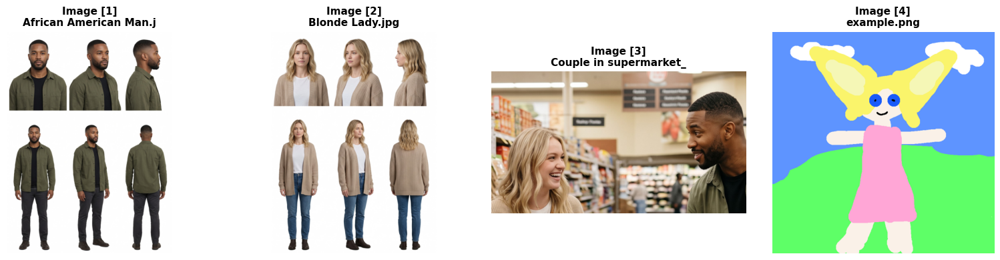


No reference videos in the Media Bank yet.

--- 🔊 Audio Bank Inventory (2 audio files) ---
Audio [1]: Calm woman.mp3


Audio [2]: Trustworthy man.mp3


In [ ]:
# @markdown # 📥 2. Upload Images, Reference Videos & Audio and View Media Bank
import os
import math
import cv2
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display, Audio

BANK_DIR = '/content/ComfyUI/input'
os.makedirs(BANK_DIR, exist_ok=True)
os.chdir(BANK_DIR)

print(f"Upload images (.png/.jpg/.webp/.jfif), reference videos (.mp4/.mov/.webm/.mkv), and/or audio (.wav/.mp3/.flac) to {BANK_DIR} (optional — cancel if already uploaded or running T2V):")
uploaded = files.upload()
os.chdir('/content/ComfyUI')

all_files = os.listdir(BANK_DIR)
available_images = sorted([f for f in all_files if f.lower().endswith(('.png', '.jpg', '.jpeg', '.webp', '.jfif'))])
available_videos = sorted([f for f in all_files if f.lower().endswith(('.mp4', '.mov', '.webm', '.mkv', '.avi'))])
available_audios = sorted([f for f in all_files if f.lower().endswith(('.wav', '.mp3', '.flac', '.ogg', '.m4a'))])

if available_images:
    print(f"\n--- 🖼️ Image Bank Inventory ({len(available_images)} images) ---")
    cols = 4
    rows = math.ceil(len(available_images) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
    axes = [axes] if (rows == 1 and cols == 1) else axes.flatten()

    for i, img_name in enumerate(available_images):
        img = Image.open(os.path.join(BANK_DIR, img_name))
        img.thumbnail((512, 512))
        axes[i].imshow(img)
        axes[i].set_title(f"Image [{i+1}]\n{img_name[:22]}", fontsize=11, fontweight='bold')
        axes[i].axis('off')

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("\nNo images in the Media Bank yet.")

if available_videos:
    print(f"\n--- 🎞️ Video Bank Inventory ({len(available_videos)} videos) ---")
    cols = 4
    rows = math.ceil(len(available_videos) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
    axes = [axes] if (rows == 1 and cols == 1) else axes.flatten()

    for i, vid_name in enumerate(available_videos):
        vpath = os.path.join(BANK_DIR, vid_name)
        cap = cv2.VideoCapture(vpath)
        ret, frame = cap.read()
        v_w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH) or 0)
        v_h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT) or 0)
        v_fps = cap.get(cv2.CAP_PROP_FPS) or 0.0
        v_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT) or 0)
        cap.release()
        v_dur = (v_frames / v_fps) if v_fps > 0 else 0.0
        if ret:
            thumb = Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            thumb.thumbnail((512, 512))
            axes[i].imshow(thumb)
        axes[i].set_title(
            f"Video [{i+1}]\n{vid_name[:22]}\n{v_w}x{v_h} | {v_frames}f ({v_dur:.1f}s @ {v_fps:.0f}fps)",
            fontsize=10, fontweight='bold'
        )
        axes[i].axis('off')

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("\nNo reference videos in the Media Bank yet.")

if available_audios:
    print(f"\n--- 🔊 Audio Bank Inventory ({len(available_audios)} audio files) ---")
    for i, aud_name in enumerate(available_audios):
        print(f"Audio [{i+1}]: {aud_name}")
        display(Audio(filename=os.path.join(BANK_DIR, aud_name)))
else:
    print("\nNo audio files in the Media Bank yet.")


In [ ]:
# @markdown # 🎯 3. Select Optional Keyframes, Reference Images, Reference Videos, Reference Audios & Enter Prompts
# @markdown Leave any slot empty to skip it. Numbers match the Media Bank indices printed in Cell 2.
import os

BANK_DIR = '/content/ComfyUI/input'
os.makedirs(BANK_DIR, exist_ok=True)
all_files = os.listdir(BANK_DIR)
available_images = sorted([f for f in all_files if f.lower().endswith(('.png', '.jpg', '.jpeg', '.webp', '.jfif'))])
available_videos = sorted([f for f in all_files if f.lower().endswith(('.mp4', '.mov', '.webm', '.mkv', '.avi'))])
available_audios = sorted([f for f in all_files if f.lower().endswith(('.wav', '.mp3', '.flac', '.ogg', '.m4a'))])

# @markdown ### **Optional Target Keyframes (Image-to-Video)**
first_frame_number = "3" # @param {type:"string"}
middle_frame_number = "" # @param {type:"string"}
last_frame_number = "" # @param {type:"string"}

# @markdown ### **Optional Subject Reference Images (`<Picture 1>`, `<Picture 2>`, `<Picture 3>`)**
ref_image_1_number = "2" # @param {type:"string"}
ref_image_2_number = "1" # @param {type:"string"}
ref_image_3_number = "" # @param {type:"string"}

# @markdown ### **Optional Reference Videos (`ref_video_1`, `ref_video_2` from Video Bank)**
ref_video_1_number = "" # @param {type:"string"}
ref_video_2_number = "" # @param {type:"string"}

# @markdown ### **Optional Reference Video Audios (`ref_video_audio_1`..`4` from Audio Bank)**
# @markdown *Leave empty to auto-extract the embedded audio from your selected reference video(s) when `auto_extract_ref_video_audio` is enabled in Cell 4.*
ref_video_audio_1_number = "" # @param {type:"string"}
ref_video_audio_2_number = "" # @param {type:"string"}
ref_video_audio_3_number = "" # @param {type:"string"}
ref_video_audio_4_number = "" # @param {type:"string"}

# @markdown ### **Optional Voice-Timbre Reference Audios (`<Audio 1>`..`<Audio 4>` from Audio Bank)**
ref_audio_1_number = "1" # @param {type:"string"}
ref_audio_2_number = "2" # @param {type:"string"}
ref_audio_3_number = "" # @param {type:"string"}
ref_audio_4_number = "" # @param {type:"string"}

def get_file_path(num_str, file_list, label):
    if num_str.strip().isdigit():
        idx = int(num_str.strip()) - 1
        if 0 <= idx < len(file_list):
            return os.path.join(BANK_DIR, file_list[idx])
        print(f"⚠️ Warning: {label} [{num_str.strip()}] is out of range (1..{len(file_list)}).")
    return None

first_frame_path = get_file_path(first_frame_number, available_images, "Image")
middle_frame_path = get_file_path(middle_frame_number, available_images, "Image")
last_frame_path = get_file_path(last_frame_number, available_images, "Image")

ref_image_paths = {
    "ref_image_1": get_file_path(ref_image_1_number, available_images, "Image"),
    "ref_image_2": get_file_path(ref_image_2_number, available_images, "Image"),
    "ref_image_3": get_file_path(ref_image_3_number, available_images, "Image"),
}

ref_video_paths = {
    "ref_video_1": get_file_path(ref_video_1_number, available_videos, "Video"),
    "ref_video_2": get_file_path(ref_video_2_number, available_videos, "Video"),
}

ref_video_audio_paths = {
    "ref_video_audio_1": get_file_path(ref_video_audio_1_number, available_audios, "Audio"),
    "ref_video_audio_2": get_file_path(ref_video_audio_2_number, available_audios, "Audio"),
    "ref_video_audio_3": get_file_path(ref_video_audio_3_number, available_audios, "Audio"),
    "ref_video_audio_4": get_file_path(ref_video_audio_4_number, available_audios, "Audio"),
}

ref_audio_paths = {
    "ref_audio_1": get_file_path(ref_audio_1_number, available_audios, "Audio"),
    "ref_audio_2": get_file_path(ref_audio_2_number, available_audios, "Audio"),
    "ref_audio_3": get_file_path(ref_audio_3_number, available_audios, "Audio"),
    "ref_audio_4": get_file_path(ref_audio_4_number, available_audios, "Audio"),
}

print("--- Selected Keyframes ---")
print(f"  First Frame  (t=0):   {os.path.basename(first_frame_path) if first_frame_path else 'None'}")
print(f"  Middle Frame (t=mid): {os.path.basename(middle_frame_path) if middle_frame_path else 'None'}")
print(f"  Last Frame   (t=end): {os.path.basename(last_frame_path) if last_frame_path else 'None'}")

print("\n--- Selected Subject Reference Images ---")
for k, p in ref_image_paths.items():
    print(f"  {k}: {os.path.basename(p) if p else 'None'}")

print("\n--- Selected Reference Videos ---")
for k, p in ref_video_paths.items():
    print(f"  {k}: {os.path.basename(p) if p else 'None'}")

print("\n--- Selected Reference Video Audios (Manual Overrides) ---")
for k, p in ref_video_audio_paths.items():
    print(f"  {k}: {os.path.basename(p) if p else 'None (or auto-extract from ref_video)'}")

print("\n--- Selected Voice Reference Audios ---")
for k, p in ref_audio_paths.items():
    print(f"  {k}: {os.path.basename(p) if p else 'None'}")


# ==============================================================================
# MULTI-LINE PROMPT EDITOR (PERSISTS ACROSS CELL 3 RE-RUNS)
# ==============================================================================
import ipywidgets as widgets
from IPython.display import display

DEFAULT_MAIN_PROMPT = """subject_definitions:
<Subject 1> is the young blonde American woman in <Picture 1>, with shoulder-length wavy blonde hair, wearing a beige knit cardigan over a white t-shirt, blue jeans, and a tan leather crossbody bag.
<Subject 2> is the African-American man in <Picture 2>, with a short fade haircut and neatly trimmed beard, wearing an olive green button-up overshirt over a black crew-neck tee and dark chinos.
<Audio 1> is the voice-timbre reference for <Subject 1> (S1), containing a female spoken American English vocal layer.
<Audio 2> is the voice-timbre reference for <Subject 2> (S2), containing a warm male spoken American English vocal layer.

summary:
[reference generation + audio reference] A 9-second cinematic sequence starting directly from the framing of the opening frame inside a brightly lit supermarket aisle. <Subject 2> places an item into the shopping cart and speaks playfully to <Subject 1>. <Subject 1> laughs naturally, grabs a product off the shelf, and drops it into the cart. <Subject 1> then pushes the cart forward down the aisle while <Subject 2> walks alongside her. The camera is static before smoothly tracking backward with them.

detailed_description:
The target video is in a cinematic, photorealistic contemporary American film style with bright, natural overhead grocery store lighting.
[Shot 1] The camera is locked off in a completely static frame, starting directly from the exact composition of the opening frame. <Subject 2> sets a box of pasta into the cart, turns to <Subject 1>, smiles warmly, and using the voice timbre referenced from <Audio 2>, speaks playfully: <d>[English] Alright, let's see if we can actually stick to the list tonight.</d>
[Shot 2] At 00:04.000, <Subject 1> responds with a natural laugh using <Audio 1>, picks up a carton of fresh strawberries, and tosses it into the cart.
[Shot 3] At 00:06.000, <Subject 1> pushes the cart forward down the aisle while <Subject 2> walks beside her and the camera smoothly tracks backward with them."""

STRUCTURED_TEMPLATE = """subject_definitions:
<Subject 1> is ... in <Picture 1>.
<Audio 1> is the voice-timbre reference for <Subject 1> (S1).

summary:
A cinematic sequence starting from the opening frame...

detailed_description:
[Shot 1] ...
[Shot 2] At 00:04.000, ...

overall_soundscape:
..."""

# Preserve already-typed text if Cell 3 is re-run to change media indices
prev_main = main_prompt_box.value if "main_prompt_box" in globals() else DEFAULT_MAIN_PROMPT
prev_extra = extra_details_box.value if "extra_details_box" in globals() else ""
prev_mode = extra_mode_toggle.value if "extra_mode_toggle" in globals() else "Append"

main_prompt_box = widgets.Textarea(
    value=prev_main,
    placeholder="Write or paste your main prompt here (supports multi-line paragraphs and shot breakdowns)...",
    layout=widgets.Layout(width="98%", height="300px"),
)

extra_details_box = widgets.Textarea(
    value=prev_extra,
    placeholder="Optional extra details (e.g., camera style, lighting tweaks, overall_soundscape, non_diegetic_music)...",
    layout=widgets.Layout(width="98%", height="100px"),
)

extra_mode_toggle = widgets.ToggleButtons(
    options=["Append", "Prepend", "Off"],
    value=prev_mode,
    description="Extra Details:",
    style={"description_width": "initial"},
)

btn_template = widgets.Button(description="Load Blank Template", layout=widgets.Layout(width="auto"))
btn_restore = widgets.Button(description="Restore Default", layout=widgets.Layout(width="auto"))
btn_clear_main = widgets.Button(description="Clear Main", layout=widgets.Layout(width="auto"))
btn_clear_extra = widgets.Button(description="Clear Extra", layout=widgets.Layout(width="auto"))
status_label = widgets.HTML()

def get_combined_prompt():
    main_txt = main_prompt_box.value.strip()
    extra_txt = extra_details_box.value.strip()
    mode = extra_mode_toggle.value
    if not extra_txt or mode == "Off":
        return main_txt
    if mode == "Prepend":
        return f"{extra_txt}\n\n{main_txt}" if main_txt else extra_txt
    return f"{main_txt}\n\n{extra_txt}" if main_txt else extra_txt

def _update_status(*_):
    m_len = len(main_prompt_box.value.strip())
    e_len = len(extra_details_box.value.strip())
    c_len = len(get_combined_prompt())
    status_label.value = (
        f"<small style='opacity:0.8'>Main: <b>{m_len}</b> chars | "
        f"Extra: <b>{e_len}</b> chars ({extra_mode_toggle.value}) | "
        f"Final Prompt: <b>{c_len}</b> chars — <i>Edits apply live; no need to re-run Cell 3 before running Cell 4.</i></small>"
    )

def _on_load_template(_):
    main_prompt_box.value = STRUCTURED_TEMPLATE

def _on_restore_default(_):
    main_prompt_box.value = DEFAULT_MAIN_PROMPT
    # Uncomment below if you also want Restore Default to reset Extra Details:
    # extra_details_box.value = ""
    # extra_mode_toggle.value = "Append"

btn_restore.on_click(_on_restore_default)

def _on_clear_main(_):
    main_prompt_box.value = ""

def _on_clear_extra(_):
    extra_details_box.value = ""

btn_template.on_click(_on_load_template)
btn_clear_main.on_click(_on_clear_main)
btn_clear_extra.on_click(_on_clear_extra)
main_prompt_box.observe(_update_status, names="value")
extra_details_box.observe(_update_status, names="value")
extra_mode_toggle.observe(_update_status, names="value")
_update_status()

prompt_ui = widgets.VBox([
    widgets.HTML("<hr style='margin:12px 0'><b>📝 Main Prompt</b>"),
    main_prompt_box,
    widgets.HTML("<b style='margin-top:8px; display:inline-block'>✨ Extra Details (Added to Prompt)</b>"),
    extra_details_box,
    widgets.HBox(
        [extra_mode_toggle, btn_restore, btn_template, btn_clear_main, btn_clear_extra],
        layout=widgets.Layout(gap="8px", margin="6px 0", flex_flow="row wrap"),
    ),
    status_label,
], layout=widgets.Layout(width="100%"))

display(prompt_ui)



--- Selected Keyframes ---
  First Frame  (t=0):   Couple in supermarket_edited.png
  Middle Frame (t=mid): None
  Last Frame   (t=end): None

--- Selected Subject Reference Images ---
  ref_image_1: Blonde Lady.jpg
  ref_image_2: African American Man.jpg
  ref_image_3: None

--- Selected Reference Videos ---
  ref_video_1: None
  ref_video_2: None

--- Selected Reference Video Audios (Manual Overrides) ---
  ref_video_audio_1: None (or auto-extract from ref_video)
  ref_video_audio_2: None (or auto-extract from ref_video)
  ref_video_audio_3: None (or auto-extract from ref_video)
  ref_video_audio_4: None (or auto-extract from ref_video)

--- Selected Voice Reference Audios ---
  ref_audio_1: Calm woman.mp3
  ref_audio_2: Trustworthy man.mp3
  ref_audio_3: None
  ref_audio_4: None


In [ ]:
# @title 💥 4. Generate Video / Image {"single-column":true}
import os
import gc
import math
import time
import random
import inspect
import torch
import folder_paths
from comfy import model_management
from comfy_api.latest import Types
from comfy_extras.nodes_custom_sampler import (
    BasicGuider,
    RandomNoise,
    KSamplerSelect,
    SamplerCustomAdvanced,
)
from comfy_extras.nodes_video import CreateVideo
from comfy_extras.nodes_audio import VAEDecodeAudio
from nodes import (
    UNETLoader,
    CLIPLoader,
    VAELoader,
    VAEDecode,
    VAEDecodeTiled,
    LoraLoaderModelOnly,
    LoadImage,
    SaveImage,
)
from IPython.display import clear_output, display, Image as IPImage

# @markdown ### **Prompt & Output Type**
output_type = "Video" # @param ["Video", "Single Image (1 frame)"]

# @markdown ### **Active Inputs (configured in Cell 3)**
use_first_frame = True # @param {type:"boolean"}
use_middle_frame = False # @param {type:"boolean"}
use_last_frame = False # @param {type:"boolean"}
use_ref_images = True # @param {type:"boolean"}
use_ref_videos = False # @param {type:"boolean"}
use_ref_video_audios = False # @param {type:"boolean"}
use_ref_audios = True # @param {type:"boolean"}

# @markdown ### **Reference Video Decoding Options**
auto_extract_ref_video_audio = True # @param {type:"boolean"}
ref_video_target_fps = 24.0 # @param {type:"number"}
ref_video_max_frames = 121 # @param {type:"integer"}

# @markdown ### **Resolution & Duration (Matches Workflow ResolutionSelector)**
resolution_mode = "Custom Width & Height" # @param ["Aspect Ratio & Megapixels (Workflow Default)", "Custom Width & Height"]
aspect_ratio = "16:9 (Widescreen)" # @param ["16:9 (Widescreen)", "9:16 (Vertical)", "1:1 (Square)", "4:3 (Classic)", "3:4 (Portrait)", "3:2", "2:3", "21:9 (Ultrawide)"]
megapixels = 1 # @param {type:"number"}
custom_width = 1376 # @param {type:"integer"}
custom_height = 768 # @param {type:"integer"}
resolution_source = "use provided width and height values" # @param ["use provided width and height values", "use width and height of source image first", "resize source (keep aspect ratio, fit mode: total pixels)", "resize source (keep aspect ratio, fit mode: shortest edge)", "resize source (keep aspect ratio, fit mode: longest edge)", "resize source (fit mode: stretch)"]
reference_resize_mode = "resize to start frame total_pixels" # @param ["resize to start frame total_pixels", "keep original"]
duration_seconds = 6 # @param {type:"number"}

# @markdown ### **Pika H3 Flex 6-Step Sampling & LoRA**
lora_strength = 1.0 # @param {type:"number"}
extra_lora_strength = 0.0 # @param {type:"number"}
sampler_name = "lcm" # @param ["lcm", "euler", "res_multistep", "dpmpp_2m"]
sigmas_str = "1.0, 0.972973, 0.923077, 0.8, 0.571429, 0.333333, 0.0" # @param {type:"string"}
seed = 0 # @param {type:"integer"}

# @markdown ### **Attention & Low-VRAM Optimizations (Exact Workflow Nodes)**
use_comfy_kitchen_attention = True # @param {type:"boolean"}
use_low_vram_attention = True # @param {type:"boolean"}
low_vram_head_chunks = 1 # @param {type:"integer"}
use_block_sparse_attention = True # @param {type:"boolean"}
vsa_keep_percent = 10 # @param {type:"integer"}
vsa_min_tokens = 12288 # @param {type:"integer"}
use_chunk_feed_forward = True # @param {type:"boolean"}
ffn_chunks = 4 # @param {type:"integer"}
ffn_seq_threshold = 4096 # @param {type:"integer"}
use_tiled_vae_decode = False # @param {type:"boolean"}

if "get_combined_prompt" not in globals():
    raise RuntimeError("Please run Cell 3 first to initialize the multi-line prompt editor.")
prompt_resolved = get_combined_prompt()
if not prompt_resolved:
    raise ValueError("Prompt is empty. Enter text in Cell 3's Main Prompt or Extra Details box.")

if seed == 0:
    seed = random.randint(1, 100000000000000)

# Compute resolution (matches ResolutionSelector multiple=32)
ASPECT_MAP = {
    "16:9 (Widescreen)": (16, 9),
    "9:16 (Vertical)": (9, 16),
    "1:1 (Square)": (1, 1),
    "4:3 (Classic)": (4, 3),
    "3:4 (Portrait)": (3, 4),
    "3:2": (3, 2),
    "2:3": (2, 3),
    "21:9 (Ultrawide)": (21, 9),
}

if resolution_mode == "Aspect Ratio & Megapixels (Workflow Default)":
    ar_w, ar_h = ASPECT_MAP[aspect_ratio]
    total_px = megapixels * 1_000_000.0
    width = max(32, round(math.sqrt(total_px * ar_w / ar_h) / 32) * 32)
    height = max(32, round(math.sqrt(total_px * ar_h / ar_w) / 32) * 32)
else:
    width = max(32, round(custom_width / 32) * 32)
    height = max(32, round(custom_height / 32) * 32)

# Exact frame count formula from workflow Node 131 (ComfyMathExpression):
# max(5, round(a * 24)) + (5 - (max(5, round(a * 24)) % 17)) % 17
if output_type == "Single Image (1 frame)":
    length = 1
else:
    raw_frames = max(5, int(round(duration_seconds * 24)))
    length = raw_frames + (5 - (raw_frames % 17)) % 17

def _load_optional_image(enabled, path_or_var, load_img_node):
    if not enabled:
        return None
    path = globals().get(path_or_var) if isinstance(path_or_var, str) and os.path.sep not in path_or_var else path_or_var
    if path and os.path.exists(path):
        return load_img_node.load_image(os.path.basename(path))[0]
    return None

def _parse_manual_sigmas(sigmas_text):
    """Uses ComfyUI ManualSigmas if available, with direct float32 tensor fallback."""
    ManualSigmasCls = find_comfy_node("ManualSigmas", ("comfy_extras.nodes_custom_sampler",))
    if ManualSigmasCls is not None:
        try:
            return invoke_node(ManualSigmasCls, sigmas=sigmas_text)[0]
        except Exception:
            pass
    vals = [float(x.strip()) for x in sigmas_text.replace("\n", ",").split(",") if x.strip()]
    return torch.tensor(vals, dtype=torch.float32)

def _call_combined_conditioning(
    clip, vae_video, vae_audio,
    first_t, mid_t, last_t,
    ref_imgs_dict, ref_vids_dict, ref_vid_auds_dict, ref_auds_dict
):
    """Calls MiniMaxH3CombinedImageAndReferenceToVideo cleanly across V3 Autogrow and flat-kwarg versions."""
    fn = getattr(MiniMaxH3CombinedImageAndReferenceToVideo, "execute", None)
    if fn is None:
        inst = MiniMaxH3CombinedImageAndReferenceToVideo()
        fn = getattr(inst, getattr(MiniMaxH3CombinedImageAndReferenceToVideo, "FUNCTION", "execute"))
    sig = inspect.signature(fn)
    params = sig.parameters

    kwargs = {
        "clip": clip,
        "vae": vae_video,
        "audio_vae": vae_audio,
        "prompt": prompt_resolved,
        "resolution_source": resolution_source,
        "width": width,
        "height": height,
        "length": length,
        "first_frame": first_t,
        "middle_frame": mid_t,
        "last_frame": last_t,
    }
    if "reference_resize_mode" in params:
        kwargs["reference_resize_mode"] = reference_resize_mode

    autogrow_groups = [
        ("ref_images", ref_imgs_dict),
        ("ref_videos", ref_vids_dict),
        ("ref_video_audios", ref_vid_auds_dict),
        ("ref_audios", ref_auds_dict),
    ]
    for group_name, items in autogrow_groups:
        if not items:
            continue
        if group_name in params:
            kwargs[group_name] = items
        else:
            for k, v in items.items():
                if k in params:
                    kwargs[k] = v

    has_var_kw = any(p.kind == inspect.Parameter.VAR_KEYWORD for p in params.values())
    if not has_var_kw:
        kwargs = {k: v for k, v in kwargs.items() if k in params}

    res = fn(**kwargs)
    return list(res)[:2]

def _apply_optional_model_patches(model):
    """Applies Nodes 165 -> 163 -> 166 -> 164 in exact workflow order with graceful fallback."""
    if use_comfy_kitchen_attention:
        cls = find_comfy_node("ModelAttentionBackend", ("comfy_extras.nodes_attention_multiply", "comfy_extras.nodes_model_advanced"))
        if cls is not None:
            try:
                model = invoke_node(cls, model=model, attention="comfy kitchen attention")[0]
                print("   ✓ Applied ModelAttentionBackend (comfy kitchen attention)")
            except Exception as e:
                print(f"   ⚠️ Skipped ModelAttentionBackend: {e}")

    if use_low_vram_attention:
        cls = find_comfy_node("MiniMaxLowVRAMAttention")
        if cls is not None:
            try:
                model = invoke_node(cls, model=model, head_chunks=int(low_vram_head_chunks))[0]
                print(f"   ✓ Applied MiniMaxLowVRAMAttention (head_chunks={low_vram_head_chunks})")
            except Exception as e:
                print(f"   ⚠️ Skipped MiniMaxLowVRAMAttention: {e}")

    if use_block_sparse_attention:
        cls = find_comfy_node("BlockSparseAttention", ("comfy_extras.nodes_model_advanced", "comfy_extras.nodes_sparse_attention"))
        if cls is not None:
            try:
                fn = getattr(cls, "execute", None) or getattr(cls(), getattr(cls, "FUNCTION", "execute"))
                sig_params = inspect.signature(fn).parameters
                bsa_kwargs = {
                    "model": model,
                    "selection": {"selection": "vsa", "keep_percent": int(vsa_keep_percent)},
                    "start_percent": 0.0,
                    "end_percent": 1.0,
                    "dense_blocks": "",
                    "min_tokens": int(vsa_min_tokens),
                    "extra_tokens": 256,
                    "sink_conditioning": "exact_kv_and_rows",
                    "verbose": False,
                }
                if "keep_percent" in sig_params:
                    bsa_kwargs["selection"] = "vsa"
                    bsa_kwargs["keep_percent"] = int(vsa_keep_percent)
                has_var_kw = any(p.kind == inspect.Parameter.VAR_KEYWORD for p in sig_params.values())
                if not has_var_kw:
                    bsa_kwargs = {k: v for k, v in bsa_kwargs.items() if k in sig_params}
                model = invoke_node(cls, **bsa_kwargs)[0]
                print(f"   ✓ Applied BlockSparseAttention (vsa, keep={vsa_keep_percent}%, min_tokens={vsa_min_tokens})")
            except Exception as e:
                print(f"   ⚠️ Skipped BlockSparseAttention: {e}")

    if use_chunk_feed_forward:
        cls = find_comfy_node("MiniMaxChunkFeedForward")
        if cls is not None:
            try:
                model = invoke_node(cls, model=model, chunks=int(ffn_chunks), seq_threshold=int(ffn_seq_threshold))[0]
                print(f"   ✓ Applied MiniMaxChunkFeedForward (chunks={ffn_chunks}, seq_threshold={ffn_seq_threshold})")
            except Exception as e:
                print(f"   ⚠️ Skipped MiniMaxChunkFeedForward: {e}")

    return model

def generate_pika_h3_flex():
    model = clip = vae_video = vae_audio = None
    cond_out = latent_out = sampled_out = decoded_images = decoded_audio = None

    try:
        with torch.inference_mode():
            # ---------------------------------------------------------
            # STAGE 1: Load Active Inputs & Encode Conditioning
            # ---------------------------------------------------------
            load_img = LoadImage()
            first_tensor = _load_optional_image(use_first_frame, "first_frame_path", load_img)
            middle_tensor = _load_optional_image(use_middle_frame, "middle_frame_path", load_img)
            last_tensor = _load_optional_image(use_last_frame, "last_frame_path", load_img)

            ref_imgs = {}
            if use_ref_images:
                for k, p in globals().get("ref_image_paths", {}).items():
                    if p and os.path.exists(p):
                        ref_imgs[k] = load_img.load_image(os.path.basename(p))[0]

            ref_vids = {}
            ref_vid_auds = {}
            if use_ref_videos:
                for idx, (k, p) in enumerate(globals().get("ref_video_paths", {}).items(), start=1):
                    if p and os.path.exists(p):
                        print(f"    Decoding {k} ({os.path.basename(p)})...")
                        v_tensor = load_video_frames(
                            p,
                            target_fps=float(ref_video_target_fps),
                            max_frames=int(ref_video_max_frames),
                        )
                        ref_vids[k] = v_tensor
                        print(f"    ✓ Loaded {k}: {tuple(v_tensor.shape)}")
                        # Auto-extract embedded audio track if requested and no manual override exists
                        manual_aud_key = f"ref_video_audio_{idx}"
                        manual_aud_path = globals().get("ref_video_audio_paths", {}).get(manual_aud_key)
                        if auto_extract_ref_video_audio and not (use_ref_video_audios and manual_aud_path):
                            max_aud_sec = (
                                (int(ref_video_max_frames) / float(ref_video_target_fps))
                                if (ref_video_max_frames and ref_video_max_frames > 0 and ref_video_target_fps > 0)
                                else 0.0
                            )
                            extracted = extract_video_audio(p, max_duration_sec=max_aud_sec)
                            if extracted is not None:
                                ref_vid_auds[manual_aud_key] = extracted
                                print(f"    ✓ Auto-extracted {manual_aud_key} from {os.path.basename(p)} ({extracted['sample_rate']} Hz)")

            if use_ref_video_audios:
                for k, p in globals().get("ref_video_audio_paths", {}).items():
                    if p and os.path.exists(p):
                        ref_vid_auds[k] = load_audio_file(p)
                        print(f"    ✓ Loaded manual {k}: {os.path.basename(p)}")

            ref_auds = {}
            if use_ref_audios:
                for k, p in globals().get("ref_audio_paths", {}).items():
                    if p and os.path.exists(p):
                        ref_auds[k] = load_audio_file(p)

            roles = []
            if first_tensor is not None: roles.append("First")
            if middle_tensor is not None: roles.append("Middle")
            if last_tensor is not None: roles.append("Last")
            if ref_imgs: roles.append(f"{len(ref_imgs)} RefImg")
            if ref_vids: roles.append(f"{len(ref_vids)} RefVid")
            if ref_vid_auds: roles.append(f"{len(ref_vid_auds)} RefVidAud")
            if ref_auds: roles.append(f"{len(ref_auds)} RefAudio")
            mode_label = " + ".join(roles) if roles else "Text-Only (T2V/T2I)"

            sigmas = _parse_manual_sigmas(sigmas_str)
            num_steps = max(1, len(sigmas) - 1)
            print(f"🎬 Seed: {seed} | Size: {width}x{height} | Frames: {length} | Steps: {num_steps} ({sampler_name}) | Mode: {mode_label}")

            print("1/4 Loading Qwen3-VL 32B Text Encoder...")
            clip = CLIPLoader().load_clip(text_enc_file, type="minimax", device="default")[0]

            if any(x is not None for x in (first_tensor, middle_tensor, last_tensor)) or ref_imgs or ref_vids:
                print("    Loading Video VAE (for keyframe / reference image & video encoding)...")
                vae_video = VAELoader().load_vae(video_vae_file)[0]

            if ref_auds or ref_vid_auds:
                print("    Loading Audio VAE (for reference audio / ref_video_audio encoding)...")
                vae_audio = VAELoader().load_vae(audio_vae_file)[0]

            print("    Encoding prompt & conditioning via MiniMaxH3CombinedImageAndReferenceToVideo...")
            cond_out, latent_out = _call_combined_conditioning(
                clip, vae_video, vae_audio,
                first_tensor, middle_tensor, last_tensor,
                ref_imgs, ref_vids, ref_vid_auds, ref_auds
            )

            # Immediately purge 32B Text Encoder, VAEs, and reference tensors before loading Diffusion Model
            clip = vae_video = vae_audio = None
            first_tensor = middle_tensor = last_tensor = None
            ref_imgs = ref_vids = ref_vid_auds = ref_auds = None
            model_management.unload_all_models()
            gc.collect()
            torch.cuda.empty_cache()

            # ---------------------------------------------------------
            # STAGE 2: Load Base Diffusion Model + Pika H3 Flex LoRA + Patches
            # ---------------------------------------------------------
            print(f"2/4 Loading Diffusion Model ({unet_file})...")
            if unet_file.lower().endswith(".gguf"):
                from custom_nodes.ComfyUI_GGUF.nodes import UnetLoaderGGUF
                model = UnetLoaderGGUF().load_unet(unet_file)[0]
            else:
                model = UNETLoader().load_unet(unet_file, weight_dtype="default")[0]

            if lora_file and lora_strength != 0:
                print(f"    Applying LoRA ({lora_file}, strength={lora_strength})...")
                model = LoraLoaderModelOnly().load_lora_model_only(model, lora_file, float(lora_strength))[0]

            if globals().get("extra_lora_file") and extra_lora_strength != 0:
                print(f"    Applying Extra LoRA ({extra_lora_file}, strength={extra_lora_strength})...")
                model = LoraLoaderModelOnly().load_lora_model_only(model, extra_lora_file, float(extra_lora_strength))[0]

            model = _apply_optional_model_patches(model)

            # ---------------------------------------------------------
            # STAGE 3: 6-Step LCM Sampling (SamplerCustomAdvanced)
            # ---------------------------------------------------------
            print(f"3/4 Running {num_steps}-step sampling ({sampler_name})...")
            guider = invoke_node(BasicGuider, model=model, conditioning=cond_out)[0]
            noise = invoke_node(RandomNoise, noise_seed=seed)[0]
            sampler = invoke_node(KSamplerSelect, sampler_name=sampler_name)[0]

            sampled_out = invoke_node(
                SamplerCustomAdvanced,
                noise=noise,
                guider=guider,
                sampler=sampler,
                sigmas=sigmas,
                latent_image=latent_out,
            )[0]

            # Purge Diffusion Model from VRAM before Video/Audio VAE decoding
            model = guider = sampler = cond_out = latent_out = None
            model_management.unload_all_models()
            gc.collect()
            torch.cuda.empty_cache()

            # ---------------------------------------------------------
            # STAGE 4: Video VAE Decode, Audio VAE Decode & Save Output
            # ---------------------------------------------------------
            print("4/4 Decoding Video via Video VAE...")
            vae_video = VAELoader().load_vae(video_vae_file)[0]
            if use_tiled_vae_decode:
                decoded_images = invoke_node(
                    VAEDecodeTiled,
                    samples=sampled_out,
                    vae=vae_video,
                    tile_size=512,
                    overlap=64,
                    temporal_size=64,
                    temporal_overlap=8,
                )[0]
            else:
                decoded_images = invoke_node(VAEDecode, samples=sampled_out, vae=vae_video)[0]

            vae_video = None
            model_management.unload_all_models()
            gc.collect()
            torch.cuda.empty_cache()

            timestamp = time.strftime("%Y%m%d_%H%M%S")
            output_prefix = f"Pika_H3_Flex_REF2V_{timestamp}"

            if length == 1:
                print("    Saving Single Image Output...")
                SaveImage().save_images(images=decoded_images, filename_prefix=output_prefix)
                out_dir = folder_paths.get_output_directory()
                matches = sorted([
                    os.path.join(out_dir, f) for f in os.listdir(out_dir)
                    if f.startswith(output_prefix) and f.endswith((".png", ".jpg"))
                ])
                clear_output()
                if matches:
                    print(f"✅ Saved ({mode_label}): {matches[-1]}")
                    display(IPImage(filename=matches[-1]))
                else:
                    print("❌ Image saved, but file could not be located.")
            else:
                print("    Decoding Audio via Audio VAE & Exporting MP4...")
                vae_audio = VAELoader().load_vae(audio_vae_file)[0]
                decoded_audio = invoke_node(VAEDecodeAudio, samples=sampled_out, vae=vae_audio)[0]

                vae_audio = None
                model_management.unload_all_models()
                gc.collect()
                torch.cuda.empty_cache()

                created_video = invoke_node(
                    CreateVideo,
                    images=decoded_images,
                    fps=24.0,
                    audio=decoded_audio,
                    bit_depth="auto",
                    color_space="sRGB",
                    chroma_subsampling="auto",
                    codec="none",
                )[0]

                w_vid, h_vid = created_video.get_dimensions()
                full_output_folder, filename, counter, _, _ = folder_paths.get_save_image_path(
                    output_prefix,
                    folder_paths.get_output_directory(),
                    w_vid,
                    h_vid,
                )
                ext = Types.VideoContainer.get_extension("auto")
                final_output_path = os.path.join(full_output_folder, f"{filename}_{counter:05}_.{ext}")

                created_video.save_to(
                    final_output_path,
                    format=Types.VideoContainer("auto"),
                    codec="auto",
                    metadata=None,
                )

                clear_output()
                print(f"✅ Saved ({mode_label}): {final_output_path}")
                display_video(final_output_path)

    finally:
        model = clip = vae_video = vae_audio = None
        cond_out = latent_out = sampled_out = decoded_images = decoded_audio = None
        model_management.unload_all_models()
        gc.collect()
        torch.cuda.empty_cache()

generate_pika_h3_flex()


✅ Saved (First + 2 RefImg + 2 RefAudio): /content/ComfyUI/output/Pika_H3_Flex_REF2V_20261126_165048_00001_.mp4
